# Экзаменационная задача №01. Оценка эффективности внедрения облачной CRM

**Дисциплина:** Экономика информатизации, лекция №1
**Студент:** Грошев Степан Сергеевич, группа БИ 5-1
**Дата:** 2026-11-12

In [1]:
# ======================================================================
# ЭКЗАМЕНАЦИОННАЯ ЗАДАЧА №01: ОЦЕНКА ЭКОНОМИЧЕСКОЙ ЭФФЕКТИВНОСТИ ВНЕДРЕНИЯ ОБЛАЧНОЙ CRM
# ======================================================================
# Дисциплина: Экономика информатизации (лекция №1)
# Дата: 2026-11-12
# Студент: Грошев Степан Сергеевич
# Группа: БИ 5-1
# ======================================================================

# Подключение библиотек и общих утилит проекта
import sys, math
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # корень репозитория: utils/
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils.calculations import npv, irr, payback_period, discounted_payback_period, present_values, annuity_factor, fmt_rub
from utils.visualization import setup_style, thousands_axis, bar_labels, tornado, PALETTE
setup_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}".replace(",", " "))
pd.set_option("display.width", 140)

## 1. Экономическая постановка задачи

Компания «ТехноПром» думает, внедрять ли облачную CRM в отделе продаж (15 менеджеров).
Затраты: лицензии и месяц на адаптацию, когда сотрудники работают медленнее.
Выгода: менеджеры тратят меньше времени на рутину, а продажи растут.

**Цель:** оценить проект на 3 года и решить, внедрять CRM или нет.

**Что нужно сделать:**
1. Посчитать экономию на зарплате и доход от роста продаж.
2. Посчитать затраты: лицензии за 3 года и потери на адаптацию.
3. Найти чистую прибыль, NPV (ставка 12 %), срок окупаемости и ROI.
4. Описать неденежные эффекты и парадокс Солоу.

CRM хороший пример ИТ-проекта: часть выгоды легко посчитать (время, выручка), часть нет (качество сервиса, данные
о клиентах). Как раз на таких проектах видна проблема измерения отдачи от ИТ и парадокс Солоу (лекция №1).

## 2. Исходные данные

Все цифры из условия задачи. Допущения, которых в условии нет, перечислены ниже.

In [2]:
# 1.1. Параметры проекта (из условия)
managers = 15                 # численность отдела продаж, чел.
salary_month = 120_000        # средняя зарплата менеджера, руб./мес.
routine_share = 0.30          # доля рабочего времени на рутину без CRM
routine_saving = 0.20         # экономия времени на рутине после внедрения
sales_growth = 0.08           # рост продаж в год (умеренный прогноз)
turnover = 72_000_000         # текущий годовой оборот отдела, руб.
license_per_user = 24_000     # стоимость CRM на пользователя в год, руб.
adaptation_months = 1         # потеря времени на обучение, мес.
years = 3                     # горизонт оценки, лет
r = 0.12                      # ставка дисконтирования
tax = 0.20                    # налог на прибыль

# 1.2. Сводная таблица исходных данных
pd.DataFrame({
    "Параметр": ["Менеджеров", "Зарплата, руб./мес.", "Доля рутины", "Экономия времени на рутине",
                 "Рост продаж в год", "Оборот, руб./год", "Лицензия, руб./польз./год",
                 "Адаптация, мес.", "Горизонт, лет", "Ставка дисконтирования", "Налог на прибыль"],
    "Значение": [managers, salary_month, routine_share, routine_saving, sales_growth, turnover,
                 license_per_user, adaptation_months, years, r, tax]})

,Параметр,Значение
0,Менеджеров,15.00
1,"Зарплата, руб./мес.",120 000.00
2,Доля рутины,0.30
3,Экономия времени на рутине,0.20
4,Рост продаж в год,0.08
5,"Оборот, руб./год",72 000 000.00
6,"Лицензия, руб./польз./год",24 000.00
7,"Адаптация, мес.",1.00
8,"Горизонт, лет",3.00
9,Ставка дисконтирования,0.12


**Допущения:**
- Год 0 это внедрение: в нём только потери на адаптацию (месячный ФОТ отдела). Эффект и лицензии идут в годах 1–3.
- Доход от роста продаж считаем как в лекции: оборот × 8 %. Более осторожный вариант, где учитывается только маржа 30 %,
  есть в анализе чувствительности.
- Сэкономленное время оцениваем по зарплате: его либо тратят на продажи, либо не нанимают новых людей.
- Налог берём только с положительного прироста прибыли. Убыток года 0 налог не уменьшает (осторожная оценка).

## 3. Математическая модель

**Экономия ФОТ:**
$$E_{ФОТ} = N \cdot ЗП \cdot 12 \cdot d_{рут} \cdot s, \qquad d_{рут}\cdot s = 0{,}30\cdot0{,}20 = 6\%$$

**Доход от роста продаж:** $E_{прод} = Оборот \cdot g$

**Затраты:** лицензии $C_{лиц} = N \cdot L$ в год, потери на адаптацию $C_0 = N \cdot ЗП \cdot m$.

**Чистый денежный поток года $t$:** $CF_t = (E_t - C_t)\,(1 - T)$ при $E_t - C_t > 0$.

**Показатели:**
$$NPV = \sum_{t=0}^{3}\frac{CF_t}{(1+r)^t}, \qquad
ROI = \frac{\sum_t CF_t}{\sum_t C_t}\cdot 100\%, \qquad
PP:\ \min\{t: \textstyle\sum_{k\le t} CF_k \ge 0\}$$

Главный критерий NPV, потому что он учитывает стоимость денег во времени (лекция №8).
ROI и срок окупаемости дополнительные, их проще объяснить бизнесу.

## 4. Реализация расчёта
### 4.1. Прямые эффекты

In [3]:
# 2.1. Экономия на заработной плате
payroll_year = managers * salary_month * 12                     # годовой ФОТ отдела
routine_after = routine_share * (1 - routine_saving)            # доля рутины после CRM
saving_payroll = payroll_year * (routine_share - routine_after)  # высвобожденный ФОТ

# 2.2. Дополнительный доход от роста продаж
extra_sales = turnover * sales_growth
effect_year = saving_payroll + extra_sales

print(f"Годовой ФОТ отдела:            {fmt_rub(payroll_year)}")
print(f"Доля рутины до/после:          {routine_share:.0%} → {routine_after:.0%}")
print(f"Экономия ФОТ в год:            {fmt_rub(saving_payroll)}")
print(f"Дополнительный доход в год:    {fmt_rub(extra_sales)}")
print(f"Суммарный прямой эффект в год: {fmt_rub(effect_year)}")

Годовой ФОТ отдела:            21 600 000 руб.
Доля рутины до/после:          30% → 24%
Экономия ФОТ в год:            1 296 000 руб.
Дополнительный доход в год:    5 760 000 руб.
Суммарный прямой эффект в год: 7 056 000 руб.


### 4.2. Затраты на внедрение

In [4]:
# 2.3. Лицензии и потери от адаптации
license_year = managers * license_per_user
license_total = license_year * years
adaptation_loss = managers * salary_month * adaptation_months   # месяц ФОТ без отдачи
total_costs = license_total + adaptation_loss
print(f"Лицензии в год:           {fmt_rub(license_year)}")
print(f"Лицензии за {years} года:      {fmt_rub(license_total)}")
print(f"Потери на адаптацию (Г0): {fmt_rub(adaptation_loss)}")
print(f"Итого затраты:            {fmt_rub(total_costs)}")

Лицензии в год:           360 000 руб.
Лицензии за 3 года:      1 080 000 руб.
Потери на адаптацию (Г0): 1 800 000 руб.
Итого затраты:            2 880 000 руб.


### 4.3. Денежные потоки и показатели

In [5]:
# 2.4. Таблица денежных потоков по годам
rows = []
for t in range(years + 1):
    effect = 0 if t == 0 else effect_year
    cost = adaptation_loss if t == 0 else license_year
    ebt = effect - cost                       # прирост прибыли до налога
    tax_t = max(ebt, 0) * tax                 # налог только с положительного прироста
    rows.append({"Год": t, "Эффект": effect, "Затраты": cost, "Прибыль до налога": ebt,
                 "Налог 20%": tax_t, "Чистый поток CF": ebt - tax_t})
cf_table = pd.DataFrame(rows).set_index("Год")
cf = cf_table["Чистый поток CF"].values
cf_table["Дисконт. CF"] = present_values(cf, r)
cf_table["Накопл. дисконт. CF"] = cf_table["Дисконт. CF"].cumsum()
cf_table

,Эффект,Затраты,Прибыль до налога,Налог 20%,Чистый поток CF,Дисконт. CF,Накопл. дисконт. CF
Год,,,,,,,
0,0.00,1800000,-1 800 000.00,0.00,-1 800 000.00,-1 800 000.00,-1 800 000.00
1,7 056 000.00,360000,6 696 000.00,1 339 200.00,5 356 800.00,4 782 857.14,2 982 857.14
2,7 056 000.00,360000,6 696 000.00,1 339 200.00,5 356 800.00,4 270 408.16,7 253 265.31
3,7 056 000.00,360000,6 696 000.00,1 339 200.00,5 356 800.00,3 812 864.43,11 066 129.74


In [6]:
# 2.5. NPV, срок окупаемости, ROI
project_npv = npv(cf, r)
pp = payback_period(cf)
dpp = discounted_payback_period(cf, r)
roi_cash = cf.sum() / total_costs                       # ROI по чистому денежному потоку
roi_simple = (cf[1:].sum() - total_costs) / total_costs  # вариант "Σ чистой прибыли − Σ затрат" (как в лекции)
project_irr = irr(cf)
print(f"NPV (r = 12%):                         {fmt_rub(project_npv)}")
print(f"IRR:                                   {project_irr:.0%}")
print(f"Простой срок окупаемости:              {pp:.2f} года ≈ {pp*12:.1f} мес. после начала внедрения")
print(f"Дисконтированный срок окупаемости:     {dpp:.2f} года")
print(f"ROI = ΣCF / Σзатрат:                   {roi_cash:.0%}")
print(f"ROI = (Σ чист. прибыли − Σзатрат)/Σзатрат: {roi_simple:.0%} (консервативная запись, затраты учтены дважды)")

NPV (r = 12%):                         11 066 130 руб.
IRR:                                   293%
Простой срок окупаемости:              0.34 года ≈ 4.0 мес. после начала внедрения
Дисконтированный срок окупаемости:     0.38 года
ROI = ΣCF / Σзатрат:                   496%
ROI = (Σ чист. прибыли − Σзатрат)/Σзатрат: 458% (консервативная запись, затраты учтены дважды)


### 4.4. Анализ чувствительности

Проверим, меняется ли вывод, если сдвинуть ключевые допущения: рост продаж (0–12 %), маржа с дополнительных продаж (30 %),
экономия времени и цена лицензий.

In [7]:
def project_npv_for(sales_growth_=sales_growth, margin=1.0, saving=routine_saving, lic=license_per_user, rate=r):
    """NPV проекта при изменённых параметрах (та же логика, что и в базовом расчёте)."""
    eff = payroll_year * routine_share * saving + turnover * sales_growth_ * margin
    flows = [-managers * salary_month * adaptation_months]
    for _ in range(years):
        ebt = eff - managers * lic
        flows.append(ebt - max(ebt, 0) * tax)
    return npv(flows, rate)

scen = pd.DataFrame([
    {"Сценарий": "Базовый", "NPV, млн руб.": project_npv_for()},
    {"Сценарий": "Рост продаж 0% (только экономия времени)", "NPV, млн руб.": project_npv_for(sales_growth_=0)},
    {"Сценарий": "Рост продаж 4%", "NPV, млн руб.": project_npv_for(sales_growth_=0.04)},
    {"Сценарий": "Рост продаж 12%", "NPV, млн руб.": project_npv_for(sales_growth_=0.12)},
    {"Сценарий": "Маржа доп. продаж 30%", "NPV, млн руб.": project_npv_for(margin=0.30)},
    {"Сценарий": "Экономия времени 10% вместо 20%", "NPV, млн руб.": project_npv_for(saving=0.10)},
    {"Сценарий": "Лицензии ×2", "NPV, млн руб.": project_npv_for(lic=2 * license_per_user)},
    {"Сценарий": "Ставка 20%", "NPV, млн руб.": project_npv_for(rate=0.20)},
])
scen["NPV, млн руб."] = (scen["NPV, млн руб."] / 1e6).round(2) + 0.0
# Порог: при каком росте продаж NPV = 0?
from utils.calculations import solve_for
g_break = solve_for(lambda g: project_npv_for(sales_growth_=g), 0, -0.5, 0.5)
print(f"Рост продаж, при котором NPV = 0: {g_break:.2%}")
scen

Рост продаж, при котором NPV = 0: 0.00%


,Сценарий,"NPV, млн руб."
0,Базовый,11.07
1,Рост продаж 0% (только экономия времени),0.00
2,Рост продаж 4%,5.53
3,Рост продаж 12%,16.60
4,Маржа доп. продаж 30%,3.32
5,Экономия времени 10% вместо 20%,9.82
6,Лицензии ×2,10.37
7,Ставка 20%,9.48


## 5. Визуализация результатов

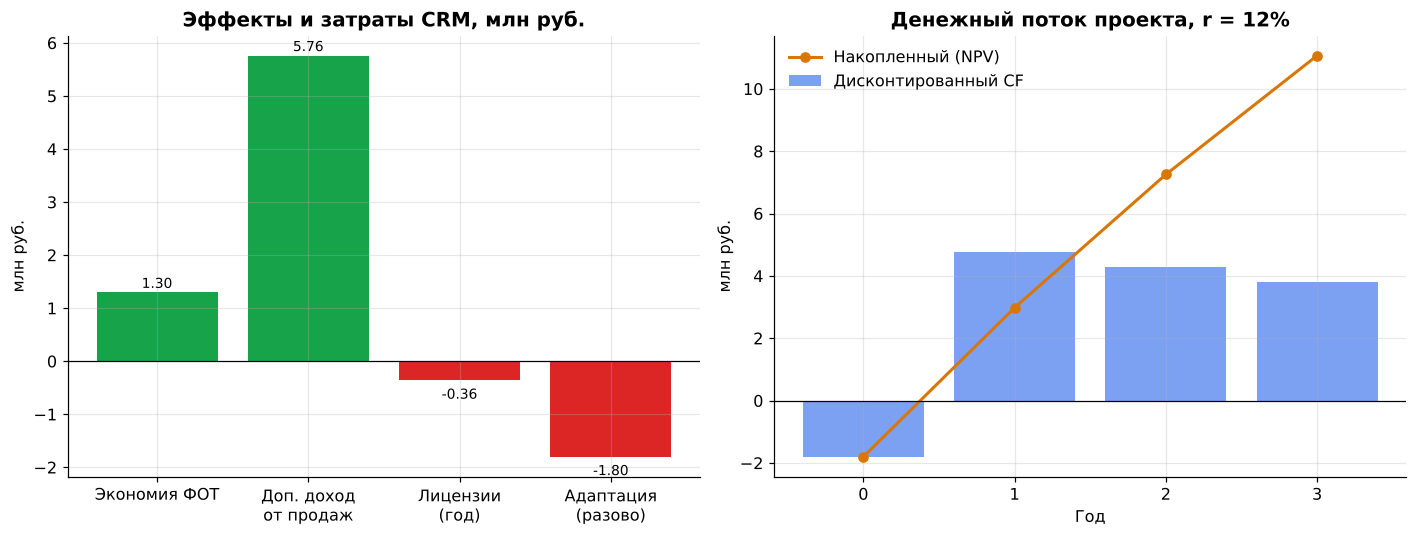

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
# Структура годового эффекта и затрат
ax = axes[0]
labels = ["Экономия ФОТ", "Доп. доход\nот продаж", "Лицензии\n(год)", "Адаптация\n(разово)"]
vals = np.array([saving_payroll, extra_sales, -license_year, -adaptation_loss]) / 1e6
bars = ax.bar(labels, vals, color=[PALETTE[2], PALETTE[2], PALETTE[1], PALETTE[1]])
bar_labels(ax, bars, "{:.2f}")
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Эффекты и затраты CRM, млн руб.")
ax.set_ylabel("млн руб.")
# Накопленный дисконтированный поток
ax = axes[1]
ax.bar(cf_table.index, cf_table["Дисконт. CF"] / 1e6, color=PALETTE[0], alpha=0.6, label="Дисконтированный CF")
ax.plot(cf_table.index, cf_table["Накопл. дисконт. CF"] / 1e6, "o-", color=PALETTE[3], lw=2, label="Накопленный (NPV)")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(cf_table.index)
ax.set_xlabel("Год")
ax.set_ylabel("млн руб.")
ax.set_title("Денежный поток проекта, r = 12%")
ax.legend()
plt.tight_layout(); plt.show()

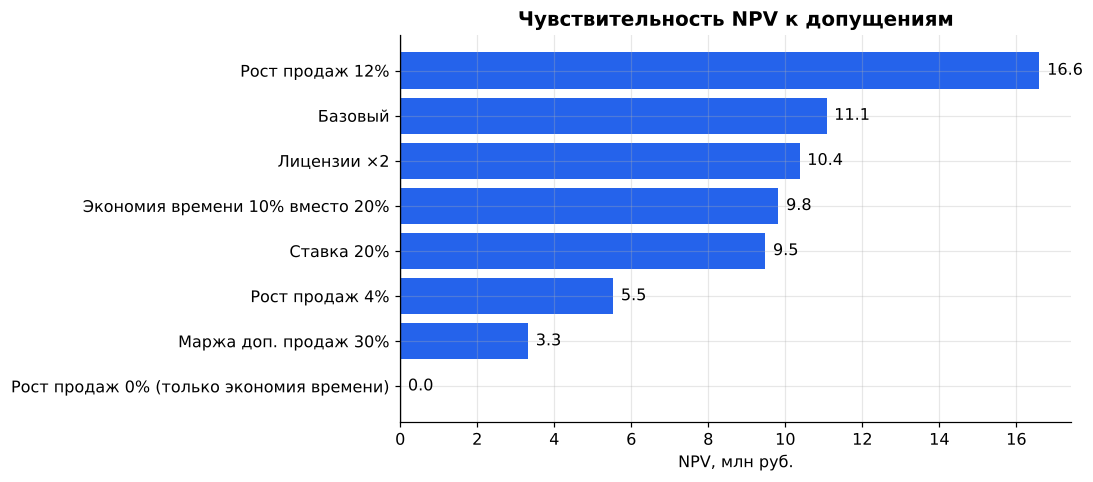

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.5))
s = scen.sort_values("NPV, млн руб.")
bars = ax.barh(s["Сценарий"], s["NPV, млн руб."], color=[PALETTE[1] if v < 0 else PALETTE[0] for v in s["NPV, млн руб."]])
for b, v in zip(bars, s["NPV, млн руб."]):
    ax.text(v + 0.2, b.get_y() + b.get_height() / 2, f"{v:.1f}", va="center")
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("NPV, млн руб.")
ax.set_title("Чувствительность NPV к допущениям")
plt.tight_layout(); plt.show()

## 6. Интерпретация результатов

**Прямые эффекты.** Экономия 6 % рабочего времени даёт около 1,3 млн руб. в год, рост продаж на 8 % около 5,8 млн руб. в год.
Примерно 80 % выгоды дают продажи. Это главный источник выгоды и одновременно главный источник риска.

**Затраты** небольшие по сравнению с эффектом: лицензии 0,36 млн руб. в год и разово 1,8 млн руб. на месяц адаптации.

**Финансовые показатели.** NPV около 11,1 млн руб., IRR во много раз выше ставки 12 %. Проект окупается примерно
за 4 месяца первого года работы. ROI по чистому потоку около 500 % (если вычитать затраты повторно, около 458 %).

**Устойчивость.** Даже без роста продаж проект выходит в ноль: одна экономия времени за 3 года покрывает лицензии
и адаптацию (NPV около 0). Значит, любой рост продаж уже делает проект выгодным. Если засчитывать только маржу 30 %
с дополнительных продаж, NPV около 3,3 млн руб. Сильнее всего на результат влияют рост продаж и маржа,
цена лицензий и ставка почти не влияют.

**Неденежные эффекты** (в расчёт не вошли):
- быстрее и лучше обслуживание клиентов, больше повторных продаж;
- база данных о клиентах остаётся у компании, а не у отдельных менеджеров;
- аналитика воронки продаж помогает точнее планировать;
- меньше **информационной асимметрии**: руководитель видит реальную загрузку и работу менеджеров;
- меньше ошибок ручного ввода.

**Парадокс Солоу** («компьютеры видны везде, кроме статистики производительности») здесь может проявиться так:
1. *Задержка эффекта.* Первые 3–6 месяцев работа может идти медленнее, а не только один месяц адаптации.
2. *Не поменяли процессы.* Без новых правил и KPI CRM станет просто дорогой записной книжкой, и продажи не вырастут.
3. *Нужны сопутствующие вложения.* Интеграция с 1С и телефонией, обучение, чистка базы. Без них эффект будет ниже.
4. *Сложно измерить.* Лояльность и качество данных не видны в бухгалтерии, поэтому эффект кажется меньше реального.
5. *Время надо использовать.* Сэкономленное время даст деньги, только если менеджеры потратят его на продажи.

## 7. Выводы и рекомендации

### 7.1. Выводы
- Проект выгоден: **NPV около 11,1 млн руб.**, окупаемость меньше года, ROI 460–500 % за 3 года.
- Вывод устойчивый: без роста продаж проект выходит в ноль, при любом росте продаж NPV положительный.
- Главный риск организационный, а не финансовый (парадокс Солоу): продажи вырастут, только если поменять процессы.

### 7.2. Рекомендации
1. **Внедрять CRM**, но начать с пилота на 5 менеджерах на 1–2 месяца, потом расширить. Так потери на адаптацию будут меньше.
2. Заложить в бюджет обучение, интеграцию с телефонией и учётной системой, чистку базы.
3. Обновить правила и KPI: привязать бонусы к ведению сделок в CRM, иначе ей не будут пользоваться.
4. До запуска зафиксировать метрики (конверсия, длина сделки, время на рутину) и сравнивать их раз в квартал.
5. Использовать данные CRM, чтобы точнее прогнозировать продажи.